# 01. Exploratory Data Analysis & Integrity Audit

### Project: E-Commerce Customer Funnel & Cohort Retention Analytics

**Objective:** Audit raw transaction logs to evaluate schema structure, detect missing identifiers, identify non-commercial transaction anomalies (returns, cancellations, test entries), and establish preprocessing boundaries for downstream analytics.

## 1. Environment Configuration & Raw Data Ingestion

In [1]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')


In [2]:
DATA_PATH = 'data/online_retail_II.xlsx'

# Ingest transaction sheets across both recorded fiscal periods
print('Ingesting raw transaction partitions...')
df_2009 = pd.read_excel(DATA_PATH, sheet_name='Year 2009-2010', engine='openpyxl')
df_2010 = pd.read_excel(DATA_PATH, sheet_name='Year 2010-2011', engine='openpyxl')

df_raw = pd.concat([df_2009, df_2010], ignore_index=True)
print(f'Ingestion complete. Total records: {len(df_raw):,}')

Ingesting raw transaction partitions...
Ingestion complete. Total records: 1,067,371


## 2. Schema Structure & Attribute Types

In [3]:
# Structural inspection
print(f'Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n')
display(df_raw.info())
display(df_raw.head())

Shape: 1,067,371 rows x 8 columns

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


None

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Data Completeness & Null Analysis

In [4]:
null_counts = df_raw.isnull().sum()
null_percentages = (null_counts / len(df_raw) * 100).round(2)

null_audit = pd.DataFrame({
    'Missing_Records': null_counts,
    'Percentage_Missing': null_percentages
}).sort_values(by='Missing_Records', ascending=False)

null_audit[null_audit['Missing_Records'] > 0]

,Missing_Records,Percentage_Missing
Customer ID,243007,22.77
Description,4382,0.41


## 4. Anomaly Diagnostics: Cancellations, Returns & Unit Economics

In [5]:
# Statistical distribution of numeric variables
display(df_raw[['Quantity', 'Price']].describe().round(2))

# Audit cancelled orders (Invoice identifiers prefixed with 'C')
cancelled_mask = df_raw['Invoice'].astype(str).str.startswith('C')
negative_qty_mask = df_raw['Quantity'] <= 0
zero_price_mask = df_raw['Price'] <= 0

print(f'Cancellation transactions : {cancelled_mask.sum():,}')
print(f'Negative/Zero quantities   : {negative_qty_mask.sum():,}')
print(f'Zero/Negative unit prices  : {zero_price_mask.sum():,}')

,Quantity,Price
count,1067371.00,1067371.00
mean,9.94,4.65
std,172.71,123.55
min,-80995.00,-53594.36
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,80995.00,38970.00


Cancellation transactions : 19,494
Negative/Zero quantities   : 22,950
Zero/Negative unit prices  : 6,207


## 5. Market Geography & Entity Cardinality

Unique Invoices : 53,628
Unique SKUs     : 5,305
Unique Customers: 5,942
Unique Countries: 43


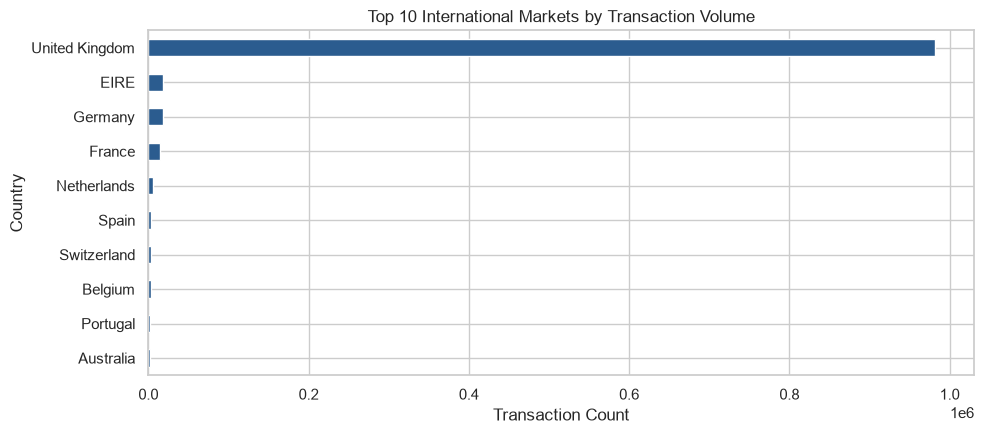

In [6]:
print(f'Unique Invoices : {df_raw["Invoice"].nunique():,}')
print(f'Unique SKUs     : {df_raw["StockCode"].nunique():,}')
print(f'Unique Customers: {df_raw["Customer ID"].nunique():,}')
print(f'Unique Countries: {df_raw["Country"].nunique():,}')

# Top 10 geographical markets by order volume
top_countries = df_raw['Country'].value_counts().head(10)

plt.figure(figsize=(10, 4.5))
top_countries.plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 International Markets by Transaction Volume', fontsize=12)
plt.xlabel('Transaction Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Preprocessing Requirements Established

1. **Missing Customer Identifiers:** ~243,000 records (~22.7%) lack `Customer ID` (unregistered guest checkouts). Because cohort retention requires deterministic tracking of customer trajectories over time, these records must be separated into a distinct analytical partition.
2. **Cancellations & Adjustments:** 19,494 records represent cancelled transactions (prefixed with `C`), while additional records contain negative quantities (returns/reversals). These must be filtered to reflect net realized purchases.
3. **Zero Unit Prices:** Transactions recorded with zero or negative price represent sample distributions, bad debts, or administrative ledger adjustments and must be excluded.
4. **Feature Engineering:** Calculate realized transaction gross value (`Quantity * Price`) and extract temporal periodicity for cohort modeling.